# 01 · Your first real embedding map

Install from the repository: `python -m pip install -e ".[demo,aef]"`.
Python 3.12+, CPU. Run all cells in order. All paths below are relative.
The small real data are bundled and SHA-256 checked by `load_demo`; corruption
raises an error. No Earth Engine login or manuscript workspace is needed.
[Full tutorial](https://github.com/GISWLH/earth-embedding/blob/main/docs/tutorials/real-demos.md).
Expected time: under one minute after installation. Download during this notebook: 0 bytes.
Source: Google / Google DeepMind AlphaEarth Foundations annual **2021**, CC-BY-4.0.
The bundled sample is a complete 72 × 88 grid of 6,336 cells covering the
San Francisco Bay Area and surroundings (about 122.54–121.48° W, 37.30–38.32° N;
92 × 113 km). Every cell inside the frame is present. It contains official
1280 m overview vectors (normalized sums of native AEF vectors), not 10 m
point samples or optical RGB. The complete checked bundle is about 2.3 MB.

In [1]:
%matplotlib inline
from pathlib import Path
from IPython.display import display
import matplotlib.pyplot as plt
import numpy as np
from earth_embedding.demo import load_demo, pca_colors, plot_map
out = Path("outputs")
out.mkdir(exist_ok=True)
print("CPU demo; outputs are saved in ./outputs")

CPU demo; outputs are saved in ./outputs


In [2]:
aef = load_demo("aef")
print(aef.features.shape)
print(aef.metadata["attribution"])
display(aef.samples.head())

(6336, 64)
The AlphaEarth Foundations Satellite Embedding dataset is produced by Google and Google DeepMind. © ESA WorldCover project 2021 / Contains modified Copernicus Sentinel data (2021) processed by ESA WorldCover consortium.


,tile_id,grid_row,grid_col,center_lon,center_lat,minlon,minlat,maxlon,maxlat,utm_easting,...,lon1,lat1,lon2,lat2,lon3,lat3,class_name,dominant_fraction,reference_valid_fraction,demo_split
0,bay_x541600_y4241280,0,0,-122.524116,38.318668,-122.531474,38.312871,-122.516757,38.324465,541600,...,-122.516833,38.312871,-122.516757,38.324406,-122.531400,38.324465,vegetation,0.958067,1,west
1,bay_x542880_y4241280,0,1,-122.509474,38.318608,-122.516833,38.312809,-122.502114,38.324406,542880,...,-122.502192,38.312809,-122.502114,38.324345,-122.516757,38.324406,vegetation,0.900760,1,west
2,bay_x544160_y4241280,0,2,-122.494832,38.318546,-122.502192,38.312746,-122.487470,38.324345,544160,...,-122.487552,38.312746,-122.487470,38.324282,-122.502114,38.324345,vegetation,0.675619,1,west
3,bay_x545440_y4241280,0,3,-122.480190,38.318482,-122.487552,38.312681,-122.472827,38.324282,545440,...,-122.472911,38.312681,-122.472827,38.324217,-122.487470,38.324282,vegetation,0.720806,1,west
4,bay_x546720_y4241280,0,4,-122.465548,38.318416,-122.472911,38.312615,-122.458184,38.324217,546720,...,-122.458270,38.312615,-122.458184,38.324150,-122.472827,38.324217,vegetation,0.987365,1,west


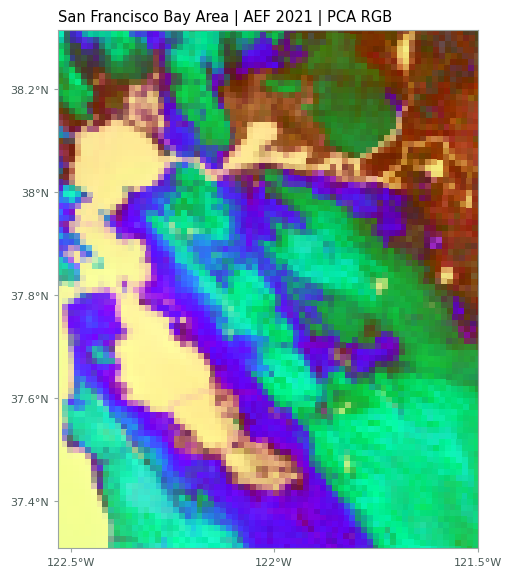

In [3]:
fig = plot_map(aef.samples, pca_colors(aef.features), title="San Francisco Bay Area | AEF 2021 | PCA RGB")
fig.savefig(out / "aef-pca.png", dpi=160)
plt.show()

Red/green/blue show the first three principal components, stretched at the
2nd/98th percentiles. PCA is fitted only for this descriptive map. Colors are
**not land-cover labels** and cannot be compared to separately fitted PCA maps.
North is up; map placement uses the stored bounds, never implicit array order.

To fetch these same points yourself, install `.[aef]`, then run
`from earth_embedding.demo import fetch_aef_demo; fresh = fetch_aef_demo()`.
This reads official COG ranges (network transfer depends on COG block layout,
potentially tens of MB), checks the expected sample SHA-256, and caches the array.
Subsequent `fetch_aef_demo(offline=True)` calls use only the checked cache.
Network errors raise a clear error; the bundled `load_demo("aef")` remains usable offline.